#### [HOME](../README.md) | [NEXT](2.OOP_Multi_Feature_Linear_Regression.ipynb)

---

# OOP Linear Regression Implementation

This Jupyter Notebook provides a basic implementation of Single Feature Linear Regression. The data set contains measurements on a single species of insect captured on two continents. We want to predict a male insect's latitude given its wing size.

#### Step 1: Import Dependencies

In [1]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error

#### Step 2: Import, Filter and Visualise The Data

In [2]:
# Import data as a Pandas DataFrame
insects = pd.read_csv('./data/insects.csv', sep='\t')
insects = pd.DataFrame({
    'continent': insects['continent'],
    'latitude': insects['latitude'],
    'sex': insects['sex'],
    'wingsize': insects['wingsize']
})

# Filter the data to only male insects
insects = insects[insects.sex == 1]

# Features variable
X_insects = insects[['wingsize']]
# Target variable
y_insects = insects['latitude']

insects.head()

,continent,latitude,sex,wingsize
21,1,35.5,1,797
22,1,37.0,1,806
23,1,38.6,1,812
24,1,40.7,1,807
25,1,40.9,1,818


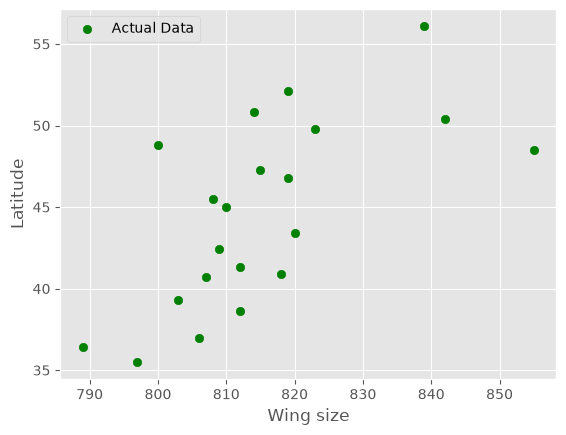

In [3]:
#Plot the data
plt.scatter(X_insects, y_insects, label="Actual Data", color='g')
plt.xlabel("Wing size")
plt.ylabel("Latitude")
plt.legend()
plt.show()

#### Step 3: Instantiate a LinearRegression Object

In [4]:
insects_regression = LinearRegression()

#### Step 4: Fit the model

In [5]:
insects_regression.fit(X_insects, y_insects)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.25]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['wingsize']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-156.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


#### Step 5: Predict Values

In [6]:
# Predict the target for the whole dataset
latitude_predictions = insects_regression.predict(X_insects)

# Predict the target for a new data point
new_insect = pd.DataFrame({
    'wingsize': [800]
})
new_insect['latitude'] = insects_regression.predict(new_insect)
print(f"New insect is:\n{new_insect}")

New insect is:
   wingsize   latitude
0       800  40.870569


#### Step 6: Plot the Predictions

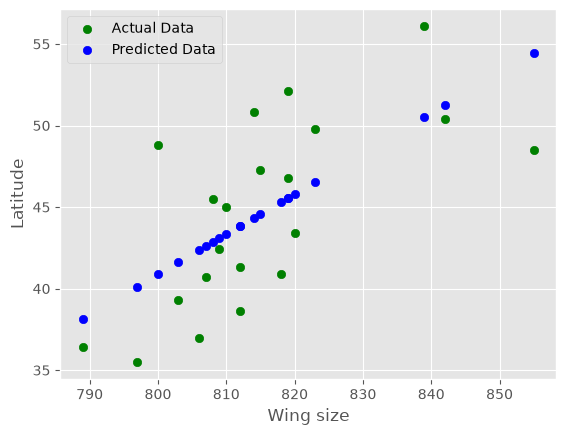

In [9]:
# Plot the predictions compared to the actual data
plt.scatter(X_insects, y_insects, label="Actual Data", color='g')
plt.scatter(X_insects, latitude_predictions, label="Predicted Data", c='b')
plt.xlabel("Wing size")
plt.ylabel("Latitude")
plt.legend()
plt.show()

#### Step 7: Evaluate The Model

In [10]:
# Get evaluative data from the model
print(f"Model coefficient: {insects_regression.coef_}")
print(f"Model y intercept: {insects_regression.intercept_}")
print(f"Model score (R squared): {insects_regression.score(X_insects, y_insects)}")
mae = mean_absolute_error(y_true=y_insects, y_pred=latitude_predictions)
mse = mean_squared_error(y_true=y_insects, y_pred=latitude_predictions)
print("MAE:", mae)
print("MSE:", mse)

Model coefficient: [0.24706008]
Model y intercept: -156.77749557179794
Model score (R squared): 0.43823454530425576
MAE: 3.6235280772732184
MSE: 17.429174492974532


In [11]:
# Optional: Manually evaluate the loss and cost of the model
model_loss = pd.DataFrame({
    'Target': y_insects,
    'Predicted result': latitude_predictions.round(2),
    'Loss': (latitude_predictions - y_insects) ** 2  # Squared error for each insect
})
# Cost = 1/(2m) x the sum of the squared errors (half of the MSE printed above)
model_cost = 1 / (2 * model_loss.shape[0]) * model_loss['Loss'].sum()

print(f"The cost of this model is {model_cost:.5f}")
print(model_loss)

The cost of this model is 8.71459
    Target  Predicted result       Loss
21    35.5             40.13  21.431243
22    37.0             42.35  28.653857
23    38.6             43.84  27.408264
24    40.7             42.60   3.609961
25    40.9             45.32  19.515638
26    42.4             43.09   0.481789
27    45.0             43.34   2.751717
28    46.8             45.56   1.525939
29    48.8             40.87  62.875872
30    49.8             46.55  10.543326
31    50.8             44.33  41.868530
32    36.4             38.15   3.072688
33    39.3             41.61   5.344186
34    41.3             43.84   6.427697
35    43.4             45.81   5.816639
36    45.5             42.85   7.038144
37    47.3             44.58   7.417613
38    48.5             54.46  35.508176
39    50.4             51.25   0.717566
40    52.1             45.56  42.710005
41    56.1             50.51  31.293816
